In [1]:
# import torch
# print(torch.__version__)
# print(torch.cuda.is_available())

# Import libs

In [1]:
import matplotlib.pyplot as plt
import scipy.io
import numpy as np

import torch
import torch.optim

from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

from models import *
from utils.custom_utils import *

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True
dtype = torch.cuda.FloatTensor

# Load image

In [ ]:
image = 'salinas_corrected'
file_name  = f'data/denoising/{image}/denoising.mat'

mat = scipy.io.loadmat(file_name)
img_np = mat["image"]
img_np = img_np.transpose(2, 0, 1)

# Noise levels
snr = 0
sparse = 0
stripe = 0

sigma = sigma_from_snr(snr, img_np)
print("sigma:", sigma)

if snr == np.inf:
    img_noisy_np = img_np
else:
    img_noisy_np = get_noisy_image(img_np, sigma, laplace=0)
img_noisy_np = create_sparse_noise(img_noisy_np, k=sparse)
img_noisy_np, striped_bands = create_stripe_noise(img_noisy_np, k=stripe)
img_noisy_var = torch.from_numpy(img_noisy_np).type(dtype)

sigma_est = sigma_estimate(img_noisy_np)
print("sigma estimate:", sigma_est)

sigma: 0.5246965686778219
sigma estimate: 0.35936584114278114


In [4]:
# print("PSNR:", psnr(np.float32(img_np), img_noisy_np))
print("MPSNR:", mpsnr(img_np, img_noisy_np))
print("SSIM:", ssim(img_np, img_noisy_np, data_range=1, channel_axis=0))

MPSNR: 8.887770461478462
SSIM: 0.042456985259343695


### Visualize

Noisy image

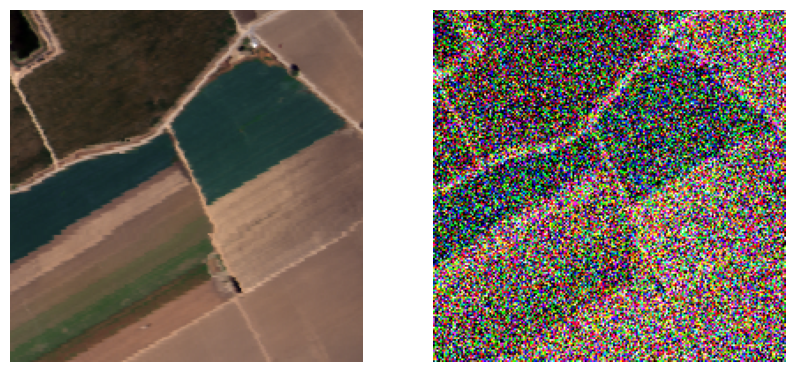

In [ ]:
if image == 'dc':
    target_bands = [56, 26, 16]
elif image == 'urban':
    target_bands = [134, 80, 26]
elif image == 'urban_full':
    target_bands = [169, 85, 30]
elif image == 'salinas_corrected':
    target_bands = [29, 19, 9]

if stripe > 0:
    bands = striped_bands[np.abs(striped_bands[:, None] - target_bands).argmin(axis=0)]
else:
    bands = target_bands

f, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(10, 10))
ax1.imshow(np.stack((img_np[bands[0],:,:], img_np[bands[1],:,:], img_np[bands[2],:,:]), 0).transpose(1, 2, 0))
ax2.imshow(np.stack((img_noisy_np[bands[0],:,:], img_noisy_np[bands[1],:,:], img_noisy_np[bands[2],:,:]), 0).transpose(1, 2, 0))
ax1.axis('off')
ax2.axis('off')
plt.show()

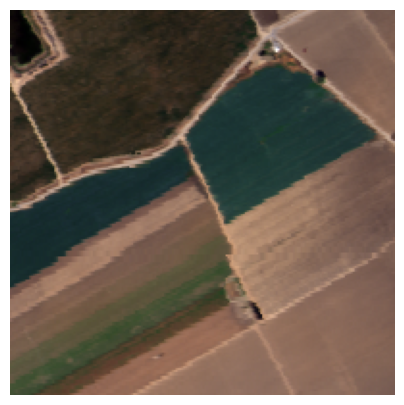

In [17]:
plt.figure(figsize=(5, 5))
plt.imshow(np.stack((img_np[bands[0],:,:], img_np[bands[1],:,:], img_np[bands[2],:,:]), 0).transpose(1, 2, 0))
plt.axis('off')
plt.savefig(f'results/{image}/original.png', bbox_inches='tight', pad_inches=0)
plt.show()

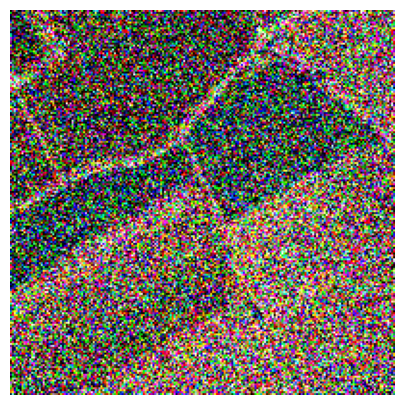

In [ ]:
if (sparse > 0) and (stripe > 0):
    noise_type = 'Gaussian + Sparse + Stripes'
elif sparse > 0:
    noise_type = 'Gaussian + Sparse'
elif stripe > 0:
    noise_type = 'Gaussian + Stripes'
else:
    noise_type = 'Gaussian'

plt.figure(figsize=(5, 5))
plt.imshow(np.stack((img_noisy_np[bands[0],:,:], img_noisy_np[bands[1],:,:], img_noisy_np[bands[2],:,:]), 0).transpose(1, 2, 0))
plt.axis('off')
plt.savefig(f'results/{image}/{noise_type}/{snr}/noisy.png', bbox_inches='tight', pad_inches=0)
plt.show()

# Setup

In [ ]:
sure = True
eps = 1e-3
norm = 1

method = '2D'
OPT_OVER = 'net,input' # 'net'

reg_noise_std = 0
LR = 0.01

OPTIMIZER = 'adam' # 'LBFGS'
exp_weight = 0.99
sstv_weight = 0
tv_weight = 0

show_every = 200
save_every = 200

num_iter = 4001
input_depth = img_np.shape[0]  

net = skip(input_depth, img_np.shape[0],
        num_channels_down=[128]*5, num_channels_up=[128]*5, num_channels_skip=[4]*5,
        filter_size_up=3, filter_size_down=3, filter_skip_size=1,
        upsample_mode='bilinear', # downsample_mode='avg',
        need1x1_up=False, need_sigmoid=True, need_bias=True, pad='reflection', act_fun='LeakyReLU').type(dtype)

img_noisy_var = img_noisy_var[None, :].cuda()

if sure:
    net_input = img_noisy_var.detach().clone()
else:
    net_input = get_noise(input_depth, method, (img_np.shape[1], img_np.shape[2])).type(dtype).detach()
    if norm == 2:
        loss = torch.nn.MSELoss().type(dtype)
    elif norm == 1:
        loss = torch.nn.SmoothL1Loss(beta=0.001).type(dtype)

# Compute number of parameters
s = sum([np.prod(list(p.size())) for p in net.parameters()]) 
print ('Number of params: %d' % s)

Number of params: 2358752


# Optimize

Starting optimization with ADAM
Iteration: 0000 Loss: 0.212442 MPSNR_gt: 12.714127 MPSNR_gt_avg: 12.714127 
SSIM_gt: 0.309039 SSIM_gt_avg: 0.309039


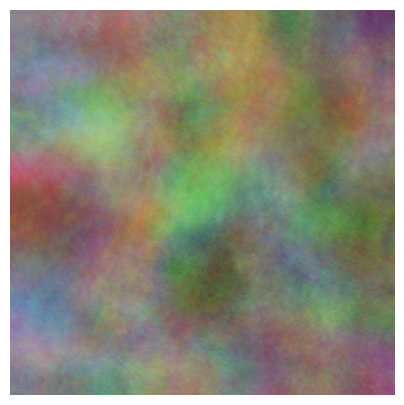

Iteration: 0200 Loss: 0.177285 MPSNR_gt: 23.405930 MPSNR_gt_avg: 23.683569 
SSIM_gt: 0.621461 SSIM_gt_avg: 0.666301


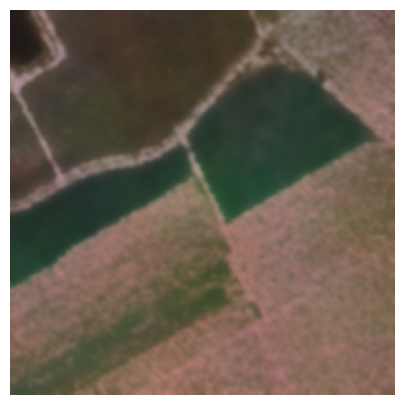

Iteration: 0400 Loss: 0.173728 MPSNR_gt: 23.289230 MPSNR_gt_avg: 24.557417 
SSIM_gt: 0.608718 SSIM_gt_avg: 0.638669


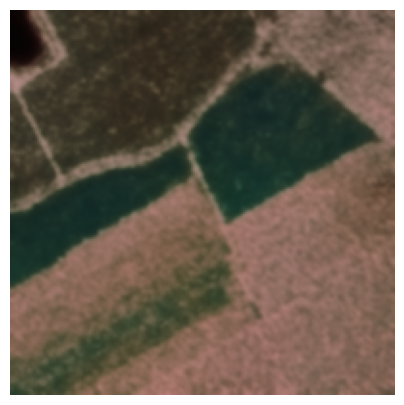

Iteration: 0600 Loss: 0.172762 MPSNR_gt: 22.290197 MPSNR_gt_avg: 23.889542 
SSIM_gt: 0.578830 SSIM_gt_avg: 0.615007


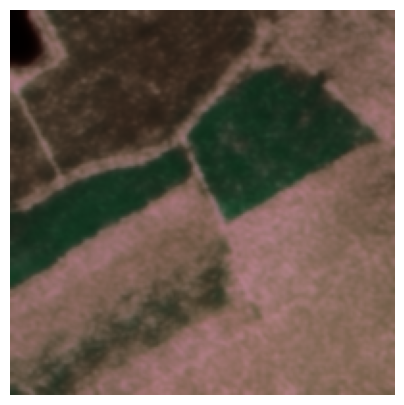

Iteration: 0800 Loss: 0.176372 MPSNR_gt: 22.544085 MPSNR_gt_avg: 23.877468 
SSIM_gt: 0.591371 SSIM_gt_avg: 0.605444


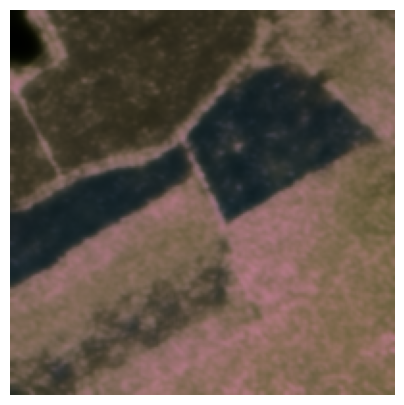

Iteration: 1000 Loss: 0.179118 MPSNR_gt: 22.090940 MPSNR_gt_avg: 23.879389 
SSIM_gt: 0.561636 SSIM_gt_avg: 0.604469


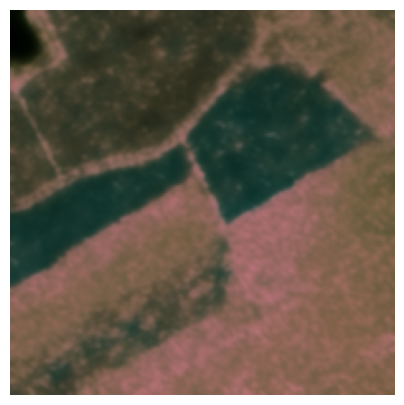

Iteration: 1200 Loss: 0.175872 MPSNR_gt: 22.630241 MPSNR_gt_avg: 23.670553 
SSIM_gt: 0.576416 SSIM_gt_avg: 0.597171


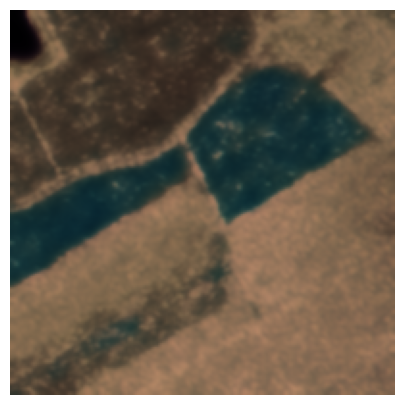

Iteration: 1400 Loss: 0.179161 MPSNR_gt: 22.913591 MPSNR_gt_avg: 23.835485 
SSIM_gt: 0.606081 SSIM_gt_avg: 0.612592


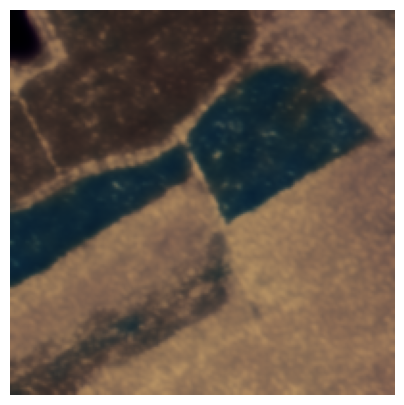

Iteration: 1600 Loss: 0.176409 MPSNR_gt: 22.863510 MPSNR_gt_avg: 24.131826 
SSIM_gt: 0.584559 SSIM_gt_avg: 0.616170


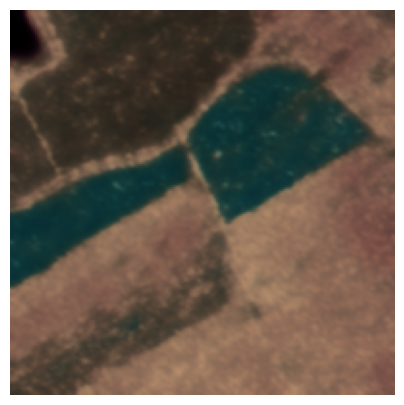

Iteration: 1800 Loss: 0.174799 MPSNR_gt: 23.324987 MPSNR_gt_avg: 24.310877 
SSIM_gt: 0.625507 SSIM_gt_avg: 0.628665


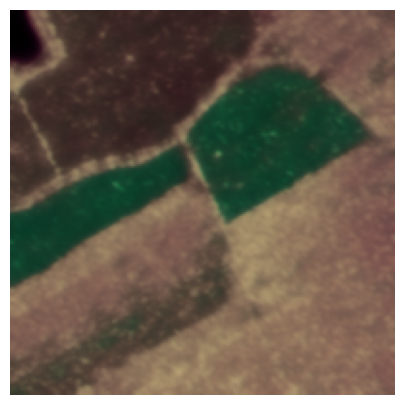

Iteration: 2000 Loss: 0.181625 MPSNR_gt: 22.878590 MPSNR_gt_avg: 24.353508 
SSIM_gt: 0.613576 SSIM_gt_avg: 0.633473


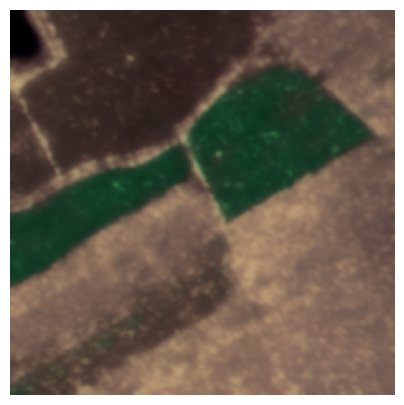

Iteration: 2200 Loss: 0.170211 MPSNR_gt: 23.128983 MPSNR_gt_avg: 24.151411 
SSIM_gt: 0.572744 SSIM_gt_avg: 0.612022


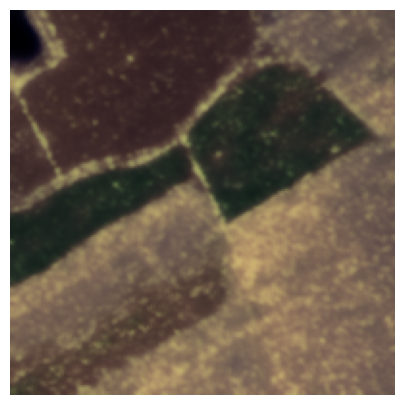

Iteration: 2400 Loss: 0.182459 MPSNR_gt: 23.431412 MPSNR_gt_avg: 24.530329 
SSIM_gt: 0.616225 SSIM_gt_avg: 0.629473


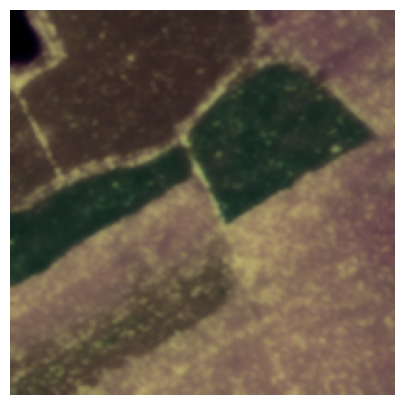

Iteration: 2600 Loss: 0.178942 MPSNR_gt: 23.200174 MPSNR_gt_avg: 24.490328 
SSIM_gt: 0.614907 SSIM_gt_avg: 0.627141


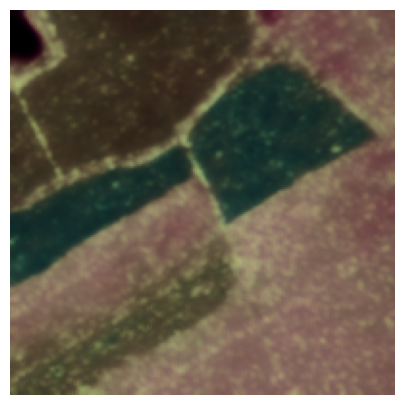

Iteration: 2800 Loss: 0.178734 MPSNR_gt: 23.346766 MPSNR_gt_avg: 24.464499 
SSIM_gt: 0.616541 SSIM_gt_avg: 0.628391


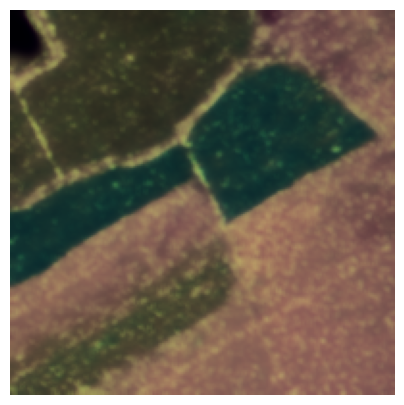

Iteration: 3000 Loss: 0.178039 MPSNR_gt: 22.843008 MPSNR_gt_avg: 24.335770 
SSIM_gt: 0.582058 SSIM_gt_avg: 0.616589


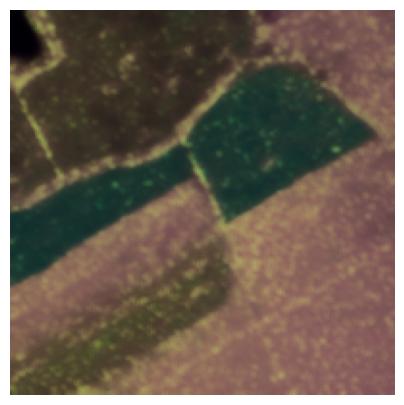

Iteration: 3200 Loss: 0.169989 MPSNR_gt: 23.671659 MPSNR_gt_avg: 24.412712 
SSIM_gt: 0.623170 SSIM_gt_avg: 0.627803


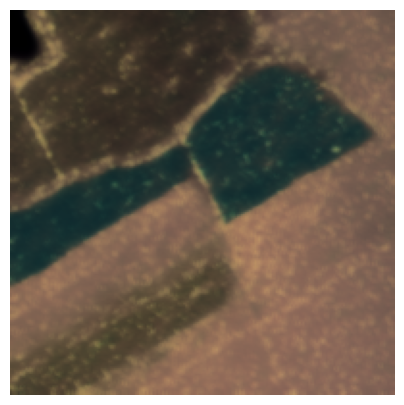

Iteration: 3400 Loss: 0.173705 MPSNR_gt: 23.660328 MPSNR_gt_avg: 24.448902 
SSIM_gt: 0.615571 SSIM_gt_avg: 0.626073


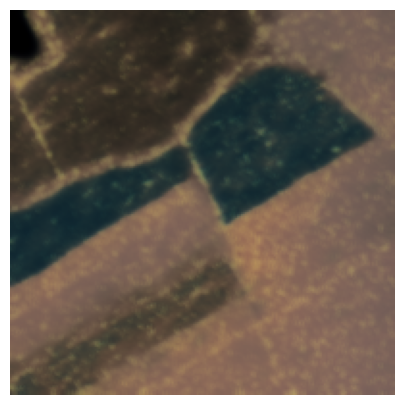

Iteration: 3600 Loss: 0.179536 MPSNR_gt: 22.164814 MPSNR_gt_avg: 23.788078 
SSIM_gt: 0.571839 SSIM_gt_avg: 0.598003


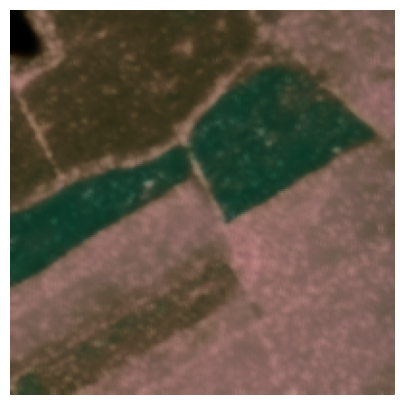

Iteration: 3800 Loss: 0.183195 MPSNR_gt: 21.602438 MPSNR_gt_avg: 23.742048 
SSIM_gt: 0.571432 SSIM_gt_avg: 0.608371


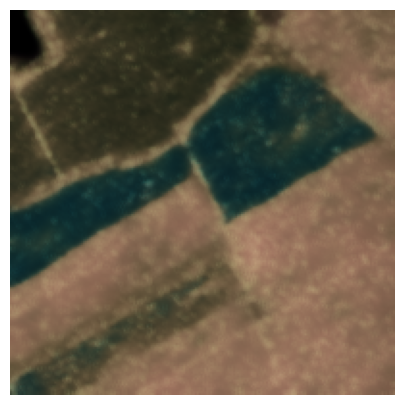

Iteration: 4000 Loss: 0.175476 MPSNR_gt: 23.011528 MPSNR_gt_avg: 23.845600 
SSIM_gt: 0.600820 SSIM_gt_avg: 0.606083


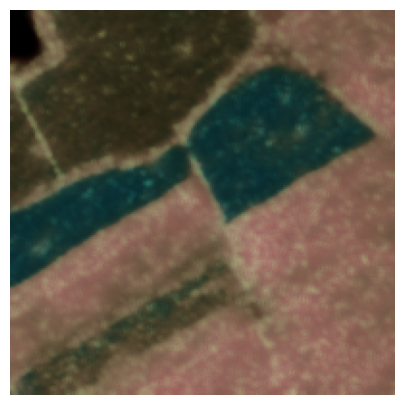

In [ ]:
net_input_saved = net_input.detach().clone()
noise = net_input.detach().clone()
out_avg = None
last_net = None
psnr_noisy_last = 0

mpsnr_list = []
ssim_list = []
nmse_list = []
loss_list = []

i = 0
def closure():
    
    global i, out_avg, psnr_noisy_last, last_net, net_input
    
    if reg_noise_std > 0:
        net_input = net_input_saved + (noise.normal_() * reg_noise_std)
    
    out = net(net_input)
    
    # Smoothing
    if out_avg is None:
        out_avg = out.detach()
    else:
        out_avg = out_avg * exp_weight + out.detach() * (1 - exp_weight)

    # Loss
    if sure:
        total_loss = sure_loss(out, img_noisy_var, sigma_est, net, epsilon=eps, norm=norm)
    elif norm == 0.5:        
        total_loss = l_half_norm(out, img_noisy_var)
    else:
        total_loss = loss(out, img_noisy_var)
    
    if sstv_weight > 0:
        total_loss += sstv_weight * sstv_loss(out)
    
    if tv_weight > 0:
        total_loss += tv_weight * tv_loss(out)
    
    total_loss.backward()
    
    net_input_np = net_input.detach().cpu().squeeze().numpy()
    out_np = out.detach().cpu().squeeze().numpy()
    out_avg_np = out_avg.detach().cpu().squeeze().numpy()

    psnr_noisy  = mpsnr(img_noisy_np.astype(np.float32), np.clip(out_np, 0, 1))
    psnr_gt     = mpsnr(img_np.astype(np.float32), np.clip(out_np, 0, 1))
    psnr_gt_avg = mpsnr(img_np.astype(np.float32), np.clip(out_avg_np, 0, 1))

    mpsnr_list.append(psnr_gt_avg)
    nmse_list.append(nmse(img_np.astype(np.float32), np.clip(out_avg_np, 0, 1)))
    loss_list.append(total_loss.item())

    print ('Iteration: %04d Loss: %f MPSNR_gt: %f MPSNR_gt_avg: %f' % (i, total_loss.item(), psnr_gt, psnr_gt_avg), '\r', end='')
    
    if i % show_every == 0:
        net_input_np = np.clip(net_input_np, 0, 1)
        out_np = np.clip(out_np, 0, 1)
        out_avg_np = np.clip(out_avg_np, 0, 1)

        mssim_gt     = ssim(img_np.astype(np.float32), out_np, data_range = 1, channel_axis = 0)
        mssim_gt_avg = ssim(img_np.astype(np.float32), out_avg_np, data_range = 1, channel_axis = 0)
        print('\n' + 'SSIM_gt: %f SSIM_gt_avg: %f' % (mssim_gt, mssim_gt_avg))
        ssim_list.append(mssim_gt_avg)
        # psnr_1 = psnr(img_np.astype(np.float32), np.clip(out_np, 0, 1))
        # psnr_2 = psnr(img_np.astype(np.float32), np.clip(out_avg_np, 0, 1))
        # print('PSNR_gt: %f PSNR_gt_avg: %f' % (psnr_1, psnr_2))
        
        # f, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(10, 10))
        # ax1.imshow(np.stack((out_np[bands[0],:,:], out_np[bands[1],:,:], out_np[bands[2],:,:]), 2))
        # ax2.imshow(np.stack((out_avg_np[bands[0],:,:], out_avg_np[bands[1],:,:], out_avg_np[bands[2],:,:]), 2))
        # ax1.axis('off')
        # ax2.axis('off')
        # plt.show()

        plt.figure(figsize=(5, 5))
        plt.imshow(np.stack((out_avg_np[bands[0],:,:], out_avg_np[bands[1],:,:], out_avg_np[bands[2],:,:]), 2))
        plt.axis('off')
        plt.savefig(f'results/{image}/{noise_type}/{snr}/output/{i}.png', bbox_inches='tight', pad_inches=0)
        plt.show()

    # if  i % save_every == 0:
        # scipy.io.savemat(f"results/{image}/mat_files/{noise_type}/{snr}/{i}.mat", {'pred':out_np.transpose(1, 2, 0), 'pred_avg':out_avg_np.transpose(1, 2, 0)})
        
    # Backtracking
    if i % show_every:
        if psnr_noisy - psnr_noisy_last < -5: 
            print('Falling back to previous checkpoint.')

            for new_param, net_param in zip(last_net, net.parameters()):
                net_param.detach().copy_(new_param.cuda())

            return total_loss*0
        else:
            last_net = [x.detach().cpu() for x in net.parameters()]
            psnr_noisy_last = psnr_noisy
            
    i += 1

    return total_loss

p = get_params(OPT_OVER, net, net_input)
optimize(OPTIMIZER, p, closure, LR, num_iter)

Training curves

In [ ]:
if sure:
    if norm == 2:
        title = 'SURE'
    elif norm == 1:
        title = r'$\ell_1 + \text{div}$'
    elif norm == 0.5:
        title = r'$\ell_{0.5}$ + div'
else:
    if norm == 2:
        title = r'\ell_2'
    elif norm == 1:
        title = r'Smooth $\ell_1$'
    elif norm == 0.5:
        title = r'$\ell_{0.5}$'

np.savez(f'results/{image}/{noise_type}/{snr}/results.npz', mpsnr=mpsnr_list, ssim=ssim_list, nmse=nmse_list, loss=loss_list)

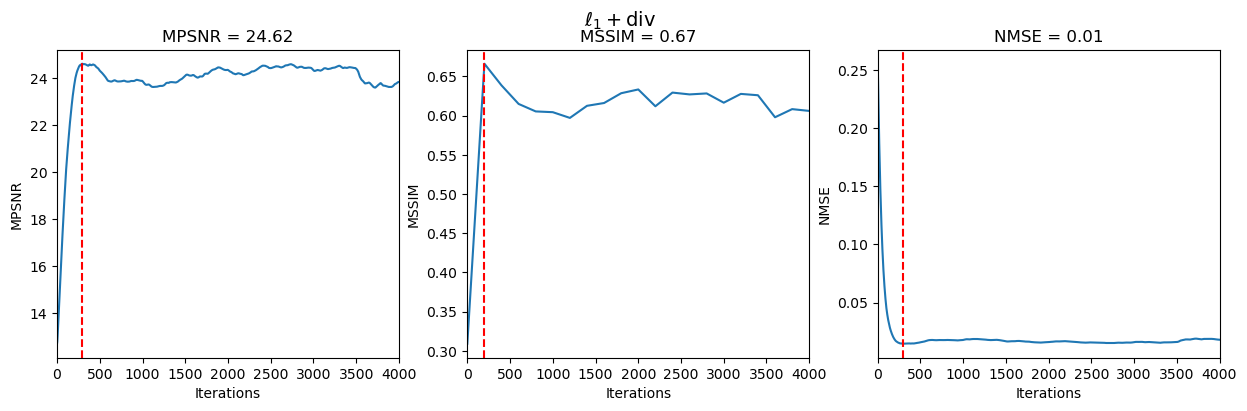

In [ ]:
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

ax1.plot(np.arange(0, num_iter), mpsnr_list)
ax1.set_title(f'MPSNR = {max(mpsnr_list):.2f}')
ax1.axvline(np.argmax(mpsnr_list), color='r', ls='--')
ax1.set_xlim(0, num_iter - 1)
ax1.set_xlabel('Iterations')
ax1.set_ylabel('MPSNR')

ax2.plot(np.arange(0, num_iter, show_every), ssim_list)
ax2.axvline(np.argmax(ssim_list)*show_every, color='r', ls='--')
ax2.set_title(f'MSSIM = {max(ssim_list):.2f}')
ax2.set_xlim(0, num_iter - 1)
ax2.set_xlabel('Iterations')
ax2.set_ylabel('MSSIM')

ax3.plot(np.arange(0, num_iter), nmse_list)
ax3.axvline(np.argmin(nmse_list), color='r', ls='--')
ax3.set_title(f'NMSE = {min(nmse_list):.2f}')
ax3.set_xlim(0, num_iter - 1)
ax3.set_xlabel('Iterations')
ax3.set_ylabel('NMSE')

plt.suptitle(title, weight='bold', fontsize=14)
plt.savefig(f'results/{image}/{noise_type}/{snr}/training_curves.png')
plt.show()

In [12]:
# no = 27
# if sure:
#     if norm == 2:
#         title = 'SURE'
#     elif norm == 1:
#         title = 'L1 + div'
#     elif norm == 0.5:
#         title = r'$L_{0.5}$ + div'
# else:
#     if norm == 2:
#         title = 'L2'
#     elif norm == 1:
#         title = 'L1'
#     elif norm == 0.5:
#         title = r'$L_{0.5}$'

# np.savez(f'results/{image}/npz_files/{no}.npz', mpsnr=mpsnr_list, ssim=ssim_list, nmse=nmse_list, loss=loss_list)

# f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# ax1.plot(np.arange(0, num_iter), mpsnr_list)
# ax1.set_title(f'MPSNR = {max(mpsnr_list):.2f}')
# ax1.axvline(np.argmax(mpsnr_list), color='r', ls='--')
# ax1.set_xlim(0, num_iter - 1)

# ax2.plot(np.arange(0, num_iter, show_every), ssim_list)
# ax2.axvline(np.argmax(ssim_list)*show_every, color='r', ls='--')
# ax2.set_title(f'SSIM = {max(ssim_list):.2f}')
# ax2.set_xlim(0, num_iter - 1)

# ax3.plot(np.arange(0, num_iter), nmse_list)
# ax3.axvline(np.argmin(nmse_list), color='r', ls='--')
# ax3.set_title(f'NMSE = {min(nmse_list):.2f}')
# ax3.set_xlim(0, num_iter - 1)

# plt.suptitle(title, weight='bold', fontsize=14)
# plt.savefig(f'results/{image}/plots/{no}.png')
# plt.show()

Training curves comparison

In [ ]:
# image = 'dc'
# num_iter = 4001
# show_every = 200

# list_mpsnr = []
# list_ssim = []
# list_nmse = []
# list_title = ['L1 + div', 'L1 + div (net + input optimization)']
# nums = '424'

# for i in [4, 24]:
#     results = np.load(f'results/{image}/npz_files/{i}.npz')
#     list_mpsnr.append(list(results['mpsnr']))
#     list_ssim.append(list(results['ssim']))
#     list_nmse.append(list(results['nmse']))

# f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# for data, title in zip(list_mpsnr, list_title):
#     ax1.plot(np.arange(0, num_iter), data, label=title)
# ax1.legend(loc='lower right')
# ax1.set_xlim(0, num_iter - 1)
# ax1.set_xlabel('Iterations')
# ax1.set_ylabel('MPSNR')
# ax1.set_title('MPSNR')

# for data, title in zip(list_ssim, list_title):
#     ax2.plot(np.arange(0, num_iter, show_every), data, label=title)
# ax2.legend(loc='lower right')
# ax2.set_xlim(0, num_iter - 1)
# ax2.set_xlabel('Iterations')
# ax2.set_ylabel('SSIM')
# ax2.set_title('SSIM')

# for data, title in zip(list_nmse, list_title):
#     ax3.plot(np.arange(0, num_iter), data, label=title)
# ax3.legend(loc='upper right')
# ax3.set_xlim(0, num_iter - 1)
# ax3.set_yscale('log')
# ax3.set_xlabel('Iterations')
# ax3.set_ylabel('NMSE')
# ax3.set_title('NMSE')

# plt.suptitle('Gaussian 10 dB + sparse 5%', weight='bold', fontsize=14)
# plt.savefig(f'results/{image}/plots/comp_{nums}.png')
# plt.show()

Load & plot single training

In [14]:
# i = 24

# image = 'dc'
# num_iter = 4001
# show_every = 200

# results = np.load(f'results/{image}/npz_files/{i}.npz')
# mpsnr_list = results['mpsnr']
# ssim_list = results['ssim']
# nmse_list = results['nmse']

# f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# ax1.plot(np.arange(0, num_iter), mpsnr_list)
# ax1.set_title(f'MPSNR = {max(mpsnr_list):.2f}')
# ax1.axvline(np.argmax(mpsnr_list), color='r', ls='--')
# ax1.set_xlim(0, num_iter - 1)
# # ax1.set_xlabel('Iterations')
# # ax1.set_ylabel('MPSNR')

# ax2.plot(np.arange(0, num_iter, show_every), ssim_list)
# ax2.axvline(np.argmax(ssim_list)*show_every, color='r', ls='--')
# ax2.set_title(f'SSIM = {max(ssim_list):.2f}')
# ax2.set_xlim(0, num_iter - 1)
# # ax2.set_xlabel('Iterations')
# # ax2.set_ylabel('SSIM')

# ax3.plot(np.arange(0, num_iter), nmse_list)
# ax3.axvline(np.argmin(nmse_list), color='r', ls='--')
# ax3.set_title(f'NMSE = {min(nmse_list):.2f}')
# ax3.set_xlim(0, num_iter - 1)
# # ax3.set_xlabel('Iterations')
# # ax3.set_ylabel('NMSE')

# plt.suptitle('L1 + div', weight='bold', fontsize=14)
# plt.savefig(f'results/{image}/plots/{i}.png')
# plt.show()